# FL-PUB-005.2 — Ablation study

*Epic EPIC-001 · story fl_pub_005 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Ablate confidentiality (HE/SecAgg/SMPC), DP and robust aggregation and their feasible combinations; document incompatible combinations.

## 2. Scientific background
Defences address different threats and can conflict (e.g. hidden updates vs server-side robust statistics) [kairouz2021].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** What does each component cost and protect against?
- **RQ2.** Which combinations are incompatible?

## 4. Hypotheses
- **H1.** Confidentiality components do not change robustness; robust/clipping components do.

## 5. Mathematical formulation
Effects relative to plain FL with CIs over seeds.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_pub_005"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_pub_005


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`fl.py`, `defenses.py`, `crypto/*`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.aggregators.mean import WeightedMean
from federated_learning.aggregators.robust import CoordinateMedian, TrimmedMean, Krum
from federated_learning.aggregators.defenses import ClippedMean
r = np.random.default_rng(SEED); D = r.normal(1.0, .05, (10, 30)).astype(np.float32); D[:2] = -50.0; W = np.ones(10)
for a in (WeightedMean(), CoordinateMedian(), TrimmedMean(0.25), Krum(2, 1)):
    print(f"{type(a).__name__:18s} max|agg-1| = {np.abs(a.aggregate(D, W) - 1.0).max():.3f}")

WeightedMean       max|agg-1| = 10.245
CoordinateMedian   max|agg-1| = 0.067
TrimmedMean        max|agg-1| = 0.077
Krum               max|agg-1| = 0.128


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-PUB-005.2` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_5_2_runs.csv')
show_csv('task_5_2_incompatible.csv')

,config,tag,seed,acc,f1,train_wall_s,up_mb,rounds_to_target,acc_under_signflip,backdoor_asr,backdoor_clean_acc,train_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain FL,-,0,0.8472,0.8019,5.2243,2.1027,21,0.3183,0.9965,0.7408,0.0000,0.0000,0.0
1,plain FL,-,1,0.8525,0.8100,5.2864,2.1027,20,0.3353,0.9972,0.7422,0.0000,0.0000,0.0
2,plain FL,-,2,0.8433,0.7967,5.3479,2.1027,21,0.5931,0.9979,0.7414,0.0000,0.0000,0.0
3,+HE (CKKS),HE,0,0.8472,0.8019,8.4710,126.4373,21,0.3183,0.9965,0.7408,62.1469,5913.2021,0.0
4,+HE (CKKS),HE,1,0.8525,0.8100,8.4766,126.3928,20,0.3353,0.9972,0.7422,60.3458,5911.0885,0.0
5,+HE (CKKS),HE,2,0.8433,0.7967,8.4634,126.4637,21,0.5931,0.9979,0.7414,58.2559,5914.4603,0.0
6,+SecAgg,SA,0,0.8472,0.8019,6.6935,5.9692,21,0.3183,0.9965,0.7408,28.1236,183.8897,0.0
7,+SecAgg,SA,1,0.8525,0.8100,6.9139,5.9692,20,0.3353,0.9972,0.7422,30.7863,183.8897,0.0
8,+SecAgg,SA,2,0.8433,0.7967,6.9901,5.9692,21,0.5931,0.9979,0.7414,30.7066,183.8897,0.0
9,+SMPC (3-party),SMPC,0,0.8472,0.8019,10.0570,12.6160,21,0.3183,0.9965,0.7408,92.5049,500.0000,0.0


,combination,reason,status
0,SecAgg + median/Krum/trimmed-mean,robust rules need per-client updates; masked u...,NOT_RUN (incompatible by construction)
1,HE (CKKS) + Krum/median,needs encrypted comparisons/sorting (deep circ...,NOT_RUN
2,plain + DP + robust (median),composition would need a separate privacy anal...,NOT_RUN


## 12. Metrics collection
Metric definitions: accuracy, overhead, accuracy under sign-flip, backdoor ASR, gradient-leakage success (from task 3.4), MIA AUC (from 3.3).

In [8]:
show_csv('task_5_2_summary.csv')

,config,acc,acc_ci,f1,f1_ci,rounds_to_target,rounds_to_target_ci,train_overhead_pct,train_overhead_pct_ci,uplink_overhead_pct,uplink_overhead_pct_ci,acc_loss_pp,acc_loss_pp_ci,acc_under_signflip,acc_under_signflip_ci,backdoor_asr,backdoor_asr_ci,server_sees_individual_updates,gradient_leakage_success_B2,gl_source,mia_auc_undefended_model
0,plain FL,0.8477,"[0.836, 0.859]",0.8029,"[0.786, 0.82]",20.6667,"[19.2, 22.1]",0.0000,"[0, 0]",0.0000,"[0, 0]",0.0000,"[0, 0]",0.4156,"[0.0331, 0.798]",0.9972,"[0.996, 0.999]",True,0.8,task 3.4 (measured there): single client B=2,0.5772304999999999
1,+HE (CKKS),0.8477,"[0.836, 0.859]",0.8029,"[0.786, 0.82]",20.6667,"[19.2, 22.1]",60.2495,"[55.4, 65.1]",5912.9170,"[5.91e+03, 5.92e+03]",0.0000,"[0, 0]",0.4156,"[0.0331, 0.798]",0.9972,"[0.996, 0.999]",False,0.0,task 3.4 (measured there): secure-aggregation ...,0.5772304999999999
2,+SecAgg,0.8477,"[0.836, 0.859]",0.8029,"[0.786, 0.82]",20.6667,"[19.2, 22.1]",29.8722,"[26.1, 33.6]",183.8897,"[184, 184]",0.0000,"[0, 0]",0.4156,"[0.0331, 0.798]",0.9972,"[0.996, 0.999]",False,0.0,task 3.4 (measured there): secure-aggregation ...,0.5772304999999999
3,+SMPC (3-party),0.8477,"[0.836, 0.859]",0.8029,"[0.786, 0.82]",20.6667,"[19.2, 22.1]",92.7490,"[66.6, 119]",500.0000,"[500, 500]",0.0000,"[0, 0]",0.4156,"[0.034, 0.797]",0.9972,"[0.996, 0.999]",False,0.0,task 3.4 (measured there): secure-aggregation ...,0.5772304999999999
4,"+DP (central, sigma=0.5)",0.8211,"[0.814, 0.828]",0.7656,"[0.755, 0.776]",21.0000,"[21, 21]",-2.5362,"[-6.45, 1.38]",0.0000,"[0, 0]",2.6574,"[0.922, 4.39]",0.7762,"[0.768, 0.784]",0.8550,"[0.6, 1.11]",True,0.8,task 3.4 (measured there): single client B=2,see task 3.3 (DP configs)
5,+robust (median),0.8460,"[0.84, 0.852]",0.8006,"[0.792, 0.81]",21.0000,"[21, 21]",-5.6885,"[-8.6, -2.78]",0.0000,"[0, 0]",0.1667,"[-0.447, 0.78]",0.8189,"[0.817, 0.821]",0.1335,"[-0.161, 0.428]",True,0.8,task 3.4 (measured there): single client B=2,0.5772304999999999
6,SecAgg + client-DP,0.8225,"[0.811, 0.834]",0.7684,"[0.752, 0.785]",21.0000,"[21, 21]",38.6802,"[34.2, 43.2]",183.8897,"[184, 184]",2.5185,"[0.269, 4.77]",0.7806,"[0.762, 0.799]",0.8570,"[0.633, 1.08]",False,0.0,task 3.4 (measured there): secure-aggregation ...,see task 3.3 (DP configs)
7,HE + client-DP,0.8225,"[0.811, 0.834]",0.7684,"[0.752, 0.785]",21.0000,"[21, 21]",70.9800,"[42.3, 99.6]",5910.5848,"[5.91e+03, 5.91e+03]",2.5185,"[0.269, 4.77]",0.7806,"[0.762, 0.799]",0.8570,"[0.633, 1.08]",False,0.0,task 3.4 (measured there): secure-aggregation ...,see task 3.3 (DP configs)
8,SMPC + norm-bound,0.8478,"[0.836, 0.859]",0.8030,"[0.786, 0.82]",20.6667,"[19.2, 22.1]",394.7630,"[381, 409]",500.0000,"[500, 500]",-0.0093,"[-0.0491, 0.0306]",0.8442,"[0.835, 0.854]",0.0458,"[-0.0948, 0.186]",False,0.0,task 3.4 (measured there): secure-aggregation ...,0.5772304999999999


## 13. Statistical analysis
CIs over seeds.

In [9]:
show_csv('task_5_2_incompatible.csv')

,combination,reason,status
0,SecAgg + median/Krum/trimmed-mean,robust rules need per-client updates; masked u...,NOT_RUN (incompatible by construction)
1,HE (CKKS) + Krum/median,needs encrypted comparisons/sorting (deep circ...,NOT_RUN
2,plain + DP + robust (median),composition would need a separate privacy anal...,NOT_RUN


## 14. Visualizations

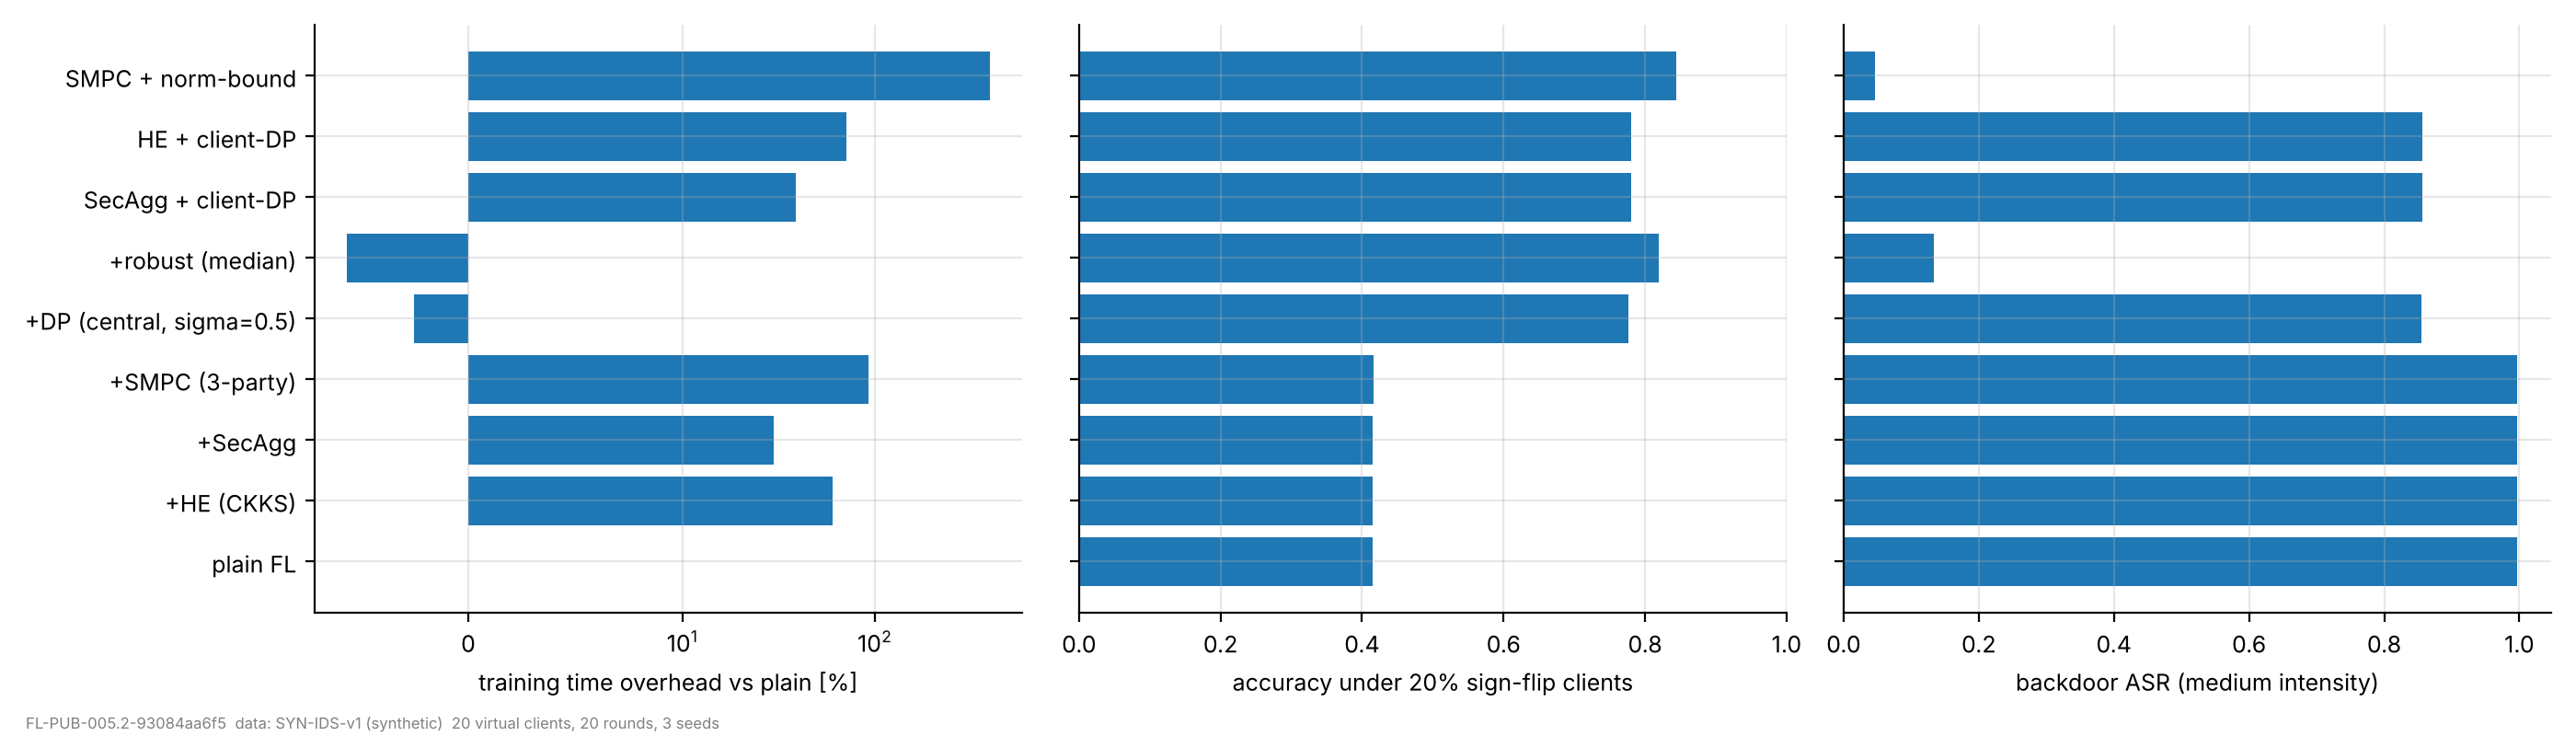

In [10]:
show_fig('task_5_2_ablation.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

See printed table; the NOT_RUN combinations are explained in the incompatible-combinations table.

In [11]:
d = pd.read_csv(RES / 'task_5_2_summary.csv'); print(d[['config','acc','train_overhead_pct','acc_under_signflip','backdoor_asr']].round(3).to_string(index=False))

                  config   acc  train_overhead_pct  acc_under_signflip  backdoor_asr
                plain FL 0.848               0.000               0.416         0.997
              +HE (CKKS) 0.848              60.250               0.416         0.997
                 +SecAgg 0.848              29.872               0.416         0.997
         +SMPC (3-party) 0.848              92.749               0.416         0.997
+DP (central, sigma=0.5) 0.821              -2.536               0.776         0.855
        +robust (median) 0.846              -5.688               0.819         0.134
      SecAgg + client-DP 0.823              38.680               0.781         0.857
          HE + client-DP 0.823              70.980               0.781         0.857
       SMPC + norm-bound 0.848             394.763               0.844         0.046


## 16. Limitations
- Gradient-leakage and MIA columns are reused from tasks 3.3/3.4, not re-measured per row.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Confidentiality and integrity need different components; no single layer covers all threats.

**Jira acceptance:** see `docs/fl_pub_005/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`kairouz2021`, `abadi2016`, `bonawitz2017` — details in `docs/fl_pub_005/references.md`.